# Employee Attrition Prediction & Workforce Intelligence
**Author:** Princeden Thi  
**Dataset:** IBM HR Analytics Employee Attrition & Performance (Kaggle)  
**Objective:** End-to-end Machine Learning pipeline to identify key attrition drivers and predict turnover risk using balanced classification models.


## 1. Environment Setup & Library Imports

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report, roc_curve
)

sns.set_theme(style='whitegrid', palette='muted')
%matplotlib inline


## 2. Dataset Loading & Inspection

In [2]:
data_path = '../data/WA_Fn-UseC_-HR-Employee-Attrition.csv'
if not os.path.exists(data_path):
    data_path = 'data/WA_Fn-UseC_-HR-Employee-Attrition.csv'
if not os.path.exists(data_path):
    data_path = 'WA_Fn-UseC_-HR-Employee-Attrition.csv'

df = pd.read_csv(data_path)
print(f'Dataset Shape: {df.shape}')
df.head()


Dataset Shape: (1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


## 3. Data Cleaning & Feature Segregation

In [3]:
# Check missing values & duplicates
print('Missing values count:', df.isnull().sum().sum())
print('Duplicate records count:', df.duplicated().sum())

# Drop constant or uninformative columns
cols_to_drop = ['EmployeeCount', 'StandardHours', 'Over18', 'EmployeeNumber']
df_clean = df.drop(columns=[c for c in cols_to_drop if c in df.columns]).drop_duplicates()
print(f'Cleaned Dataset Shape: {df_clean.shape}')

# Identify feature types
target = 'Attrition'
num_cols = df_clean.drop(columns=[target]).select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = df_clean.drop(columns=[target]).select_dtypes(include=['object', 'string']).columns.tolist()

print(f'Numerical features ({len(num_cols)}): {num_cols}')
print(f'Categorical features ({len(cat_cols)}): {cat_cols}')


Missing values count: 0
Duplicate records count: 0
Cleaned Dataset Shape: (1470, 31)
Numerical features (23): ['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']
Categorical features (7): ['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']


## 4. Exploratory Data Analysis (EDA)

C:\Users\narut\AppData\Local\Temp\ipykernel_25732\1571865958.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=target, data=df_clean, palette={'No': '#10B981', 'Yes': '#EF4444'}, ax=ax[1])


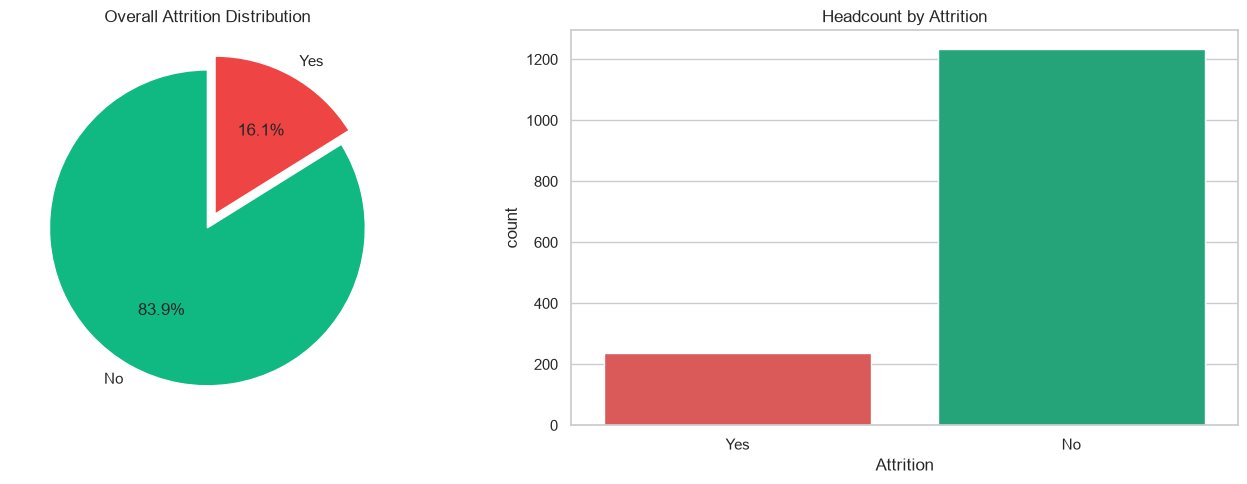

In [4]:
# Target Class Distribution
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

counts = df_clean[target].value_counts()
ax[0].pie(counts, labels=counts.index, autopct='%1.1f%%', colors=['#10B981', '#EF4444'], startangle=90, explode=(0, 0.1))
ax[0].set_title('Overall Attrition Distribution')

sns.countplot(x=target, data=df_clean, palette={'No': '#10B981', 'Yes': '#EF4444'}, ax=ax[1])
ax[1].set_title('Headcount by Attrition')
plt.tight_layout()
plt.show()


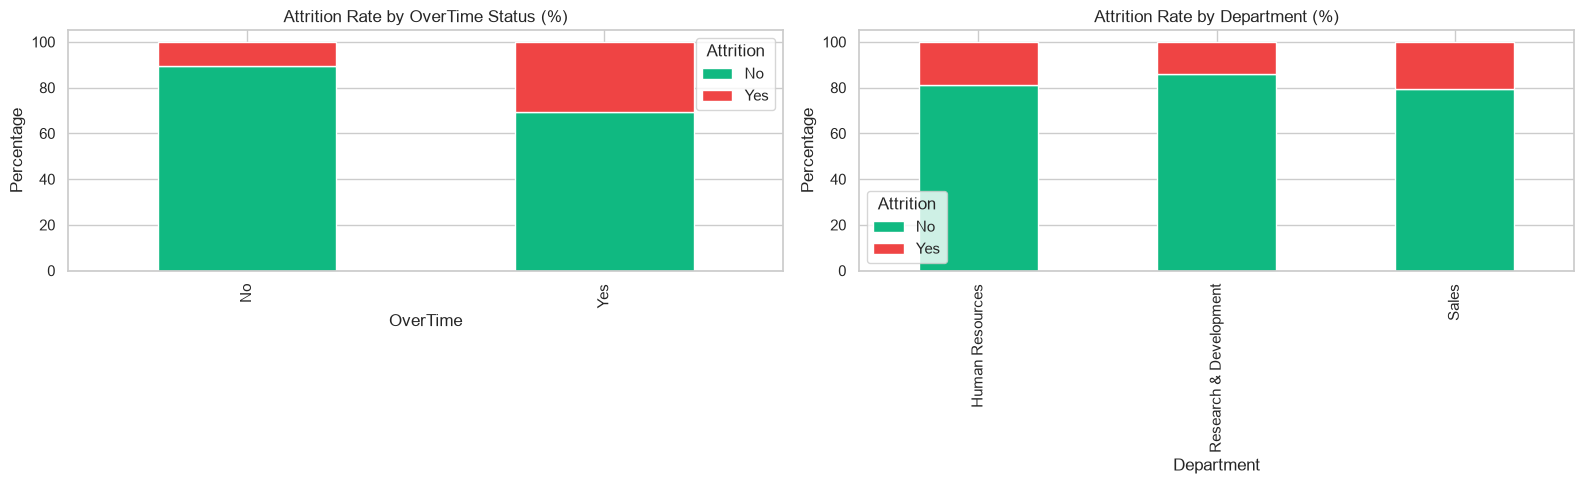

In [5]:
# Key Attrition Drivers: Overtime & Department
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Overtime
ot_df = pd.crosstab(df_clean['OverTime'], df_clean[target], normalize='index') * 100
ot_df.plot(kind='bar', stacked=True, color=['#10B981', '#EF4444'], ax=axes[0])
axes[0].set_title('Attrition Rate by OverTime Status (%)')
axes[0].set_ylabel('Percentage')

# Department
dept_df = pd.crosstab(df_clean['Department'], df_clean[target], normalize='index') * 100
dept_df.plot(kind='bar', stacked=True, color=['#10B981', '#EF4444'], ax=axes[1])
axes[1].set_title('Attrition Rate by Department (%)')
axes[1].set_ylabel('Percentage')
plt.tight_layout()
plt.show()


## 5. Stratified Train-Test Split & Preprocessing Pipeline

In [6]:
X = df_clean.drop(columns=[target])
y = df_clean[target].apply(lambda x: 1 if str(x).strip().lower() == 'yes' else 0)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f'Training Set: {X_train.shape}, Test Set: {X_test.shape}')
print(f'Train Attrition Rate: {y_train.mean():.2%}, Test Attrition Rate: {y_test.mean():.2%}')

# ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)
    ]
)


Training Set: (1176, 30), Test Set: (294, 30)
Train Attrition Rate: 16.16%, Test Attrition Rate: 15.99%


## 6. Multi-Model Training & Hyperparameter Tuning

In [7]:
models = {
    'Logistic Regression': (
        LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42),
        {'classifier__C': [0.01, 0.1, 1.0, 5.0]}
    ),
    'Decision Tree': (
        DecisionTreeClassifier(class_weight='balanced', random_state=42),
        {'classifier__max_depth': [3, 5, 8], 'classifier__min_samples_split': [5, 10]}
    ),
    'Random Forest': (
        RandomForestClassifier(class_weight='balanced', random_state=42),
        {'classifier__n_estimators': [100, 200], 'classifier__max_depth': [5, 8]}
    ),
    'Gradient Boosting': (
        GradientBoostingClassifier(random_state=42),
        {'classifier__n_estimators': [100, 150], 'classifier__learning_rate': [0.05, 0.1]}
    )
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
sample_weights_train = compute_sample_weight('balanced', y_train)

results = {}
comparison = []

for name, (clf, grid) in models.items():
    pipe = Pipeline([('preprocessor', preprocessor), ('classifier', clf)])
    search = GridSearchCV(pipe, param_grid=grid, scoring='f1', cv=cv, n_jobs=-1)
    
    if name == 'Gradient Boosting':
        search.fit(X_train, y_train, classifier__sample_weight=sample_weights_train)
    else:
        search.fit(X_train, y_train)
        
    best_pipe = search.best_estimator_
    y_pred = best_pipe.predict(X_test)
    y_proba = best_pipe.predict_proba(X_test)[:, 1] if hasattr(best_pipe, 'predict_proba') else y_pred
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    auc = roc_auc_score(y_test, y_proba)
    
    results[name] = {'pipeline': best_pipe, 'y_pred': y_pred, 'y_proba': y_proba, 'auc': auc}
    comparison.append({'Model': name, 'Accuracy': acc, 'Precision': prec, 'Recall': rec, 'F1-Score': f1, 'ROC-AUC': auc})

df_metrics = pd.DataFrame(comparison)
df_metrics


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.768707,0.382022,0.723404,0.500000,0.798518
1,Decision Tree,0.727891,0.322581,0.638298,0.428571,0.695624
2,Random Forest,0.806122,0.421875,0.574468,0.486486,0.788785
3,Gradient Boosting,0.806122,0.413793,0.510638,0.457143,0.768197


## 7. Model Evaluation & ROC Curve Analysis

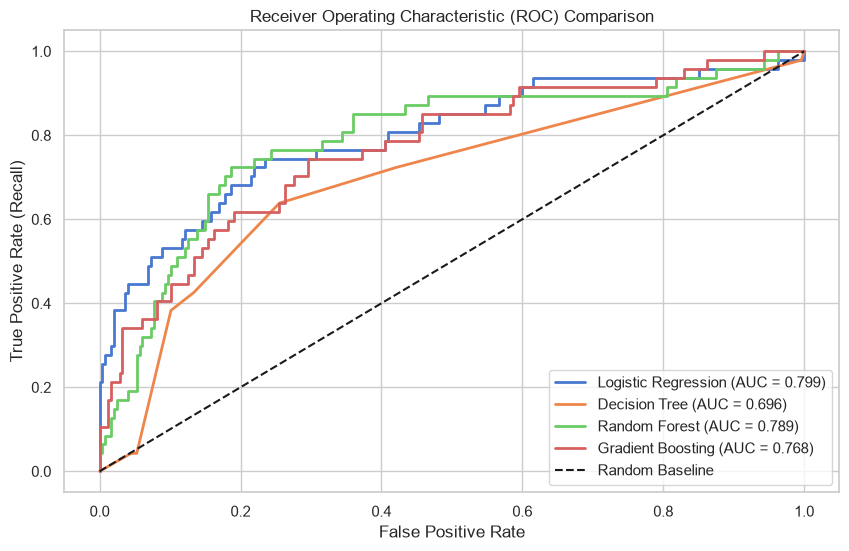

In [8]:
plt.figure(figsize=(10, 6))
for name, data in results.items():
    fpr, tpr, _ = roc_curve(y_test, data['y_proba'])
    plt.plot(fpr, tpr, label=f"{name} (AUC = {data['auc']:.3f})", lw=2)

plt.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random Baseline')
plt.title('Receiver Operating Characteristic (ROC) Comparison')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.legend(loc='lower right')
plt.show()


## 8. Champion Model Selection & Business Interpretation

In [9]:
best_model = df_metrics.sort_values(by=['F1-Score', 'Recall'], ascending=False).iloc[0]
print(f"Selected Champion Model: {best_model['Model']}")
print(f"Recall: {best_model['Recall']:.2%}, F1-Score: {best_model['F1-Score']:.4f}, ROC-AUC: {best_model['ROC-AUC']:.4f}")


Selected Champion Model: Logistic Regression
Recall: 72.34%, F1-Score: 0.5000, ROC-AUC: 0.7985
